# Approximation and error (completed)

Most of the numerical methods in this course produce an **approximation** that gets better the longer we let it run. Today: why computers approximate even simple arithmetic, how to measure the error of an approximation, and how to decide when it is good enough to stop.

In [1]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt


## Floats are approximate

A `float` stores about 16 significant digits. Everything beyond that is rounded off, which shows up as soon as two numbers of very different size meet:

In [2]:
big = 1230000000.0
med = 45.6
small = 0.0000000789
print(big + med)       
print(med + small)
print(big + small)
print(0.1 + 0.2)          # and decimal fractions are not exact in binary
print(0.1 + 0.2 == 0.3)


1230000045.6
45.6000000789
1230000000.0
0.30000000000000004
False


### Compare with caution

A loop that waits for a float to hit a value exactly may never stop. Use an inequality, or a tolerance, instead of `==` or `!=`:

In [3]:
x = 1.0
steps = 0
while x > 0:            # not `while x != 0`
    x = x - 0.1
    steps += 1
    print(f"After step {steps}, x = {x}")


After step 1, x = 0.9
After step 2, x = 0.8
After step 3, x = 0.7000000000000001
After step 4, x = 0.6000000000000001
After step 5, x = 0.5000000000000001
After step 6, x = 0.40000000000000013
After step 7, x = 0.30000000000000016
After step 8, x = 0.20000000000000015
After step 9, x = 0.10000000000000014
After step 10, x = 1.3877787807814457e-16
After step 11, x = -0.09999999999999987


## Measuring error

When we know the true value, the **true error** is $E_t = \text{true} - \text{approx}$, and the **true relative error** is $\varepsilon_t = E_t / \text{true}$ (often quoted as a percentage).

Usually we don't know the true value (why approximate it otherwise?). An iterative method gives a sequence of approximations, and the **approximate error** compares the latest two: $E_a = \text{current} - \text{previous}$ and $\varepsilon_a = E_a / \text{current}$.

### An example: the cube root of 250

One way to approximate $\sqrt[3]{a}$ is to repeat $x_{new} = (2x + a/x^2)/3$ from any starting guess. Watch both errors shrink:

In [4]:
a = 250.0
guess = 100.0
true_value = a ** (1 / 3)

print(f"{'iteration':>9} {'guess':>12} {'approx. rel. error':>20} {'true rel. error':>17}")
for i in range(1, 9):
    new_guess = (2 * guess + a / guess**2) / 3
    e_a = (new_guess - guess) / new_guess
    e_t = (true_value - new_guess) / true_value
    print(f"{i:>9} {new_guess:>12.6f} {e_a:>20.2e} {e_t:>17.2e}")
    guess = new_guess


iteration        guess   approx. rel. error   true rel. error
        1    66.675000            -5.00e-01         -9.58e+00
        2    44.468745            -4.99e-01         -6.06e+00
        3    29.687972            -4.98e-01         -3.71e+00
        4    19.886530            -4.93e-01         -2.16e+00
        5    13.468404            -4.77e-01         -1.14e+00
        6     9.438331            -4.27e-01         -4.98e-01
        7     7.227688            -3.06e-01         -1.47e-01
        8     6.413676            -1.27e-01         -1.81e-02


Both errors fall by more than a factor of 10 each iteration once the guess is close, and the approximate error tracks the true error, which is why it is a usable stand-in.

## Tolerance: deciding when to stop

A `for` loop runs a fixed number of times. What we usually want is to run *until the answer is good enough*: a `while` loop that stops when the approximate relative error drops below a **tolerance** we choose.

In [5]:
a = 250.0
guess = 100.0
true_value = a ** (1 / 3)

print(
    f"{'iteration':>9} {'guess':>12} {'approx. rel. error':>20}"
)
tol = 1e-6
e_a = 1
i = 1
while abs(e_a) > tol:
# for i in range(1, 9):
    new_guess = (2 * guess + a / guess**2) / 3
    e_a = (new_guess - guess) / new_guess
    print(f"{i:>9} {new_guess:>12.6f} {e_a:>20.2e}")
    guess = new_guess
    i += 1


iteration        guess   approx. rel. error
        1    66.675000            -5.00e-01
        2    44.468745            -4.99e-01
        3    29.687972            -4.98e-01
        4    19.886530            -4.93e-01
        5    13.468404            -4.77e-01
        6     9.438331            -4.27e-01
        7     7.227688            -3.06e-01
        8     6.413676            -1.27e-01
        9     6.301622            -1.78e-02
       10     6.299606            -3.20e-04
       11     6.299605            -1.02e-07


The pattern inside `while abs(e_a) > tol:` (compute the next approximation, measure the change, keep the new one) is the skeleton of every iterative method we'll see this quarter.

## Estimating π by throwing darts

A method that converges *slowly* makes the stopping rule more interesting. Throw darts at random at a square with an inscribed circle. The fraction that land inside the circle estimates the ratio of the areas, $\pi r^2 / 4r^2$, so $\pi \approx 4 \times \text{(darts inside)} / \text{(darts thrown)}$.

Two small functions and a loop:

In [6]:
rng = np.random.default_rng(1)

def throw_dart():
    return 2 * rng.random() - 1, 2 * rng.random() - 1   # a point in the square -1..1

def in_circle(x, y):
    return x**2 + y**2 < 1

tol = 1e-5
inside = 0
total = 0
estimate = 0.0
e_a = 1.0
estimates, errors = [], []
while abs(e_a) > tol:
    x, y = throw_dart()
    total += 1
    if in_circle(x, y):
        inside += 1
    new_estimate = 4 * inside / total
    if new_estimate == 0:        # every dart so far outside: no estimate yet
        e_a = 1.0
    else:
        e_a = (new_estimate - estimate) / new_estimate
    estimate = new_estimate
    estimates.append(estimate)
    errors.append(e_a)
print(f"pi is about {estimate:.5f} after {total} darts (true error {np.pi - estimate:.2e})")


pi is about 3.13630 after 27542 darts (true error 5.29e-03)


Plot the darts with a mask from the lesson on logical indexing, and the estimate as it settles:

true relative error 9.31e-04


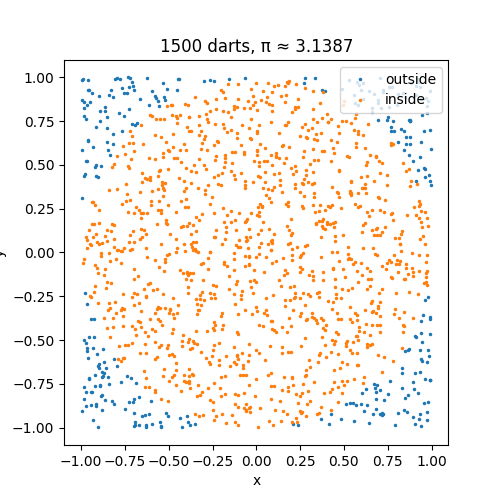

In [7]:
n = 1500
x = 2 * rng.random(n) - 1
y = 2 * rng.random(n) - 1
mask = in_circle(x, y)
pi_estimate = 4 * mask.sum() / n

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(x[~mask], y[~mask], ".", markersize=3, label="outside")
ax.plot(x[mask], y[mask], ".", markersize=3, label="inside")
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"{n} darts, π ≈ {pi_estimate:.4f}")
ax.legend(loc="upper right")
print(f"true relative error {(np.pi - pi_estimate) / np.pi:.2e}")


interactive(children=(IntSlider(value=27542, description='darts', max=27542, min=1, step=137), Output()), _dom…

Play(value=1, description='play', max=27542, min=1, step=137)

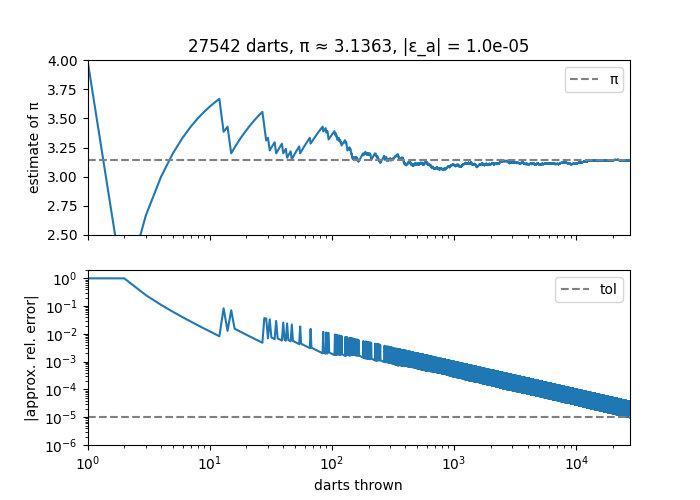

In [8]:
from ipywidgets import interact, IntSlider, Play, jslink

estimates = np.array(estimates)
errors = np.abs(errors)
n_thrown = np.arange(1, total + 1)

with plt.ioff():
    fig, (ax_est, ax_err) = plt.subplots(2, 1, sharex=True, figsize=(7, 5))
estimate_line, = ax_est.plot([], [])
ax_est.axhline(np.pi, color="gray", linestyle="--", label="π")
ax_est.set_ylim(2.5, 4)
ax_est.set_ylabel("estimate of π")
ax_est.legend(loc="upper right")

error_line, = ax_err.plot([], [])
ax_err.axhline(tol, color="gray", linestyle="--", label="tol")
ax_err.set_xscale("log")
ax_err.set_yscale("log")
ax_err.set_xlim(1, total)
ax_err.set_ylim(tol / 10, 2)
ax_err.set_xlabel("darts thrown")
ax_err.set_ylabel("|approx. rel. error|")
ax_err.legend(loc="upper right")

def update(n):
    estimate_line.set_data(n_thrown[:n], estimates[:n])
    error_line.set_data(n_thrown[:n], errors[:n])
    ax_est.set_title(f"{n} darts, π ≈ {estimates[n - 1]:.4f}, |ε_a| = {errors[n - 1]:.1e}")
    fig.canvas.draw_idle()

step = max(1, total // 200)
slider = IntSlider(min=1, max=total, step=step, value=total, description="darts")
play = Play(min=1, max=total, step=step, interval=100, description="play")
jslink((play, "value"), (slider, "value"))

interact(update, n=slider);
display(play)
display(fig.canvas)


Notice that the loop stopped when one more dart barely changed the estimate, not when the estimate was close to π. The approximate error measures the *last step*, and for a slowly converging method that is not the same as the distance to the answer. Choosing a tolerance means knowing how the method converges.

## Order of operations matters

One more consequence of floats: adding the same numbers in a different order can give a different answer. The sum $\sum 1/i^4$ converges to $\pi^4/90$; add 10,000 terms forwards and backwards.

In [9]:
n_terms = 10_000
true_value = np.pi**4 / 90

forward = 0.0
for i in range(1, n_terms + 1):
    forward += 1 / i**4

backward = 0.0
for i in range(n_terms, 0, -1):
    backward += 1 / i**4

print(f"forward:  {forward:.16f}  true rel. error {(true_value - forward) / true_value:.2e}")
print(f"backward: {backward:.16f}  true rel. error {(true_value - backward) / true_value:.2e}")


forward:  1.0823232337108610  true rel. error 2.56e-13
backward: 1.0823232337108049  true rel. error 3.08e-13


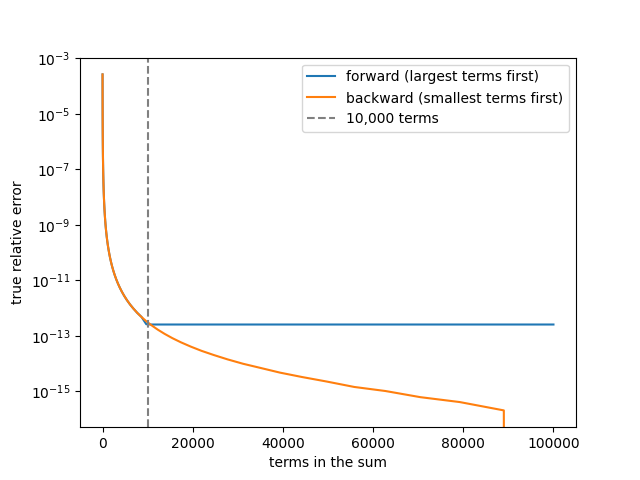

In [10]:
# repeat both sums for many lengths, from 10 terms to 100,000
lengths = np.unique(np.logspace(1, 5, 80).astype(int))
forward_errors = []
backward_errors = []
for n in lengths:
    terms = 1 / np.arange(1.0, n + 1) ** 4   # floats: n**4 overflows an integer past 55,000
    forward = sum(terms)            # Python's sum adds one term at a time, in order
    backward = sum(terms[::-1])
    forward_errors.append(abs(true_value - forward) / true_value)
    backward_errors.append(abs(true_value - backward) / true_value)

fig, ax = plt.subplots()
ax.plot(lengths, forward_errors, label="forward (largest terms first)")
ax.plot(lengths, backward_errors, label="backward (smallest terms first)")
ax.axvline(n_terms, color="gray", linestyle="--", label="10,000 terms")
ax.set_yscale("log")
ax.set_xlabel("terms in the sum")
ax.set_ylabel("true relative error")
ax.legend()


Both sums miss $\pi^4/90$ by about $3 \times 10^{-13}$, which is almost entirely the tail left out (the terms beyond 10,000 add up to about $1/(3 \cdot 10000^3)$). The two sums differ from *each other* in the 14th digit, and that difference is rounding: added forwards, the tiny late terms land on a total near 1.08 and are partly rounded away; added backwards, they accumulate first while the total is small. The backward sum is the more accurate value of the 10,000-term partial sum. This is the homework's series problem.

## Checklist

* floats hold about 16 digits; compare them with `<`, `>` or a tolerance, not `==`
* true error needs the true value; approximate error compares the last two iterations
* `while abs(e_a) > tol:` is the stopping rule for an iterative method
* the approximate error measures the last step, so a slow method can stop early